<div class="alert alert-info" role="alert"
     style="font-size: 1.55em; font-weight: bold; padding: 15px; margin: 10px 0; text-align: left; background-color: #d9edf7; border-color: #bce8f1; color: #31708f; border-radius: 8px;">
    CLARA vs OCA:  daily May-August cloud fraction over the TNA box
</div>

### Basic set up ▶▶ Libraries and helper functions

In [1]:
import xarray as xr
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.font_manager as fm
import regionmask

from scipy.stats import linregress

In [2]:
fm.fontManager.addfont("/home/nandii/cloudf/Roboto-Regular.ttf")
fm.fontManager.addfont("/home/nandii/cloudf/Roboto-Bold.ttf")
font_name = "DejaVu Sans"
for f in fm.fontManager.ttflist:
    if "roboto" in f.name.lower():
        font_name = f.name
        break
plt.rcParams["font.weight"] = "normal"
plt.rcParams["axes.titleweight"] = "bold"

In [3]:
# OLS trend on real calendar time, with significance
def trend_stats(dtime, cloud):
    x = mdates.date2num(dtime)
    x = x - x[0]
    slope, intercept, r_val, p_val, std_err = linregress(x, cloud)
    total = slope * x.max()
    y_fit = intercept + slope * x
    return {"x": x, "slope": slope, "p_val": p_val, "total": total, "y_fit": y_fit}

# Land-masked, May-Aug, box-mean daily series from a pre/post-2011 zarr pair
def bloom_series(paths, var):
    # Box trimmed to 60W-20W
    ds = xr.concat([xr.open_zarr(p)[[var]] for p in paths], dim = "time").sortby("time").sel(lon = slice(-60, -20))
    land = regionmask.defined_regions.natural_earth_v5_0_0.land_110.mask(ds.lon, ds.lat)
    cf = ds[var].where(np.isnan(land))
    cf = cf.sel(time = cf.time.dt.month.isin(bloom_months)).mean(dim = ["lat", "lon"]).compute()
    return pd.Series(cf.values, index = pd.DatetimeIndex(cf.time.values)).dropna()

### Load data ▶▶ `CLARA cfc` and `OCA cf_scene` zarrs, both split at 2011

In [4]:
bloom_months = [5, 6, 7, 8]

clara = bloom_series(["/home/nandii/cloudf/cfc_subset_1990_MJJA.zarr",
                      "/home/nandii/cloudf/cfc_subset_1991_2010.zarr",
                      "/home/nandii/cloudf/cfc_subset_2011_2026.zarr"], "cfc")
oca   = bloom_series(["/home/nandii/cloudML/OCA_sectors_ss_2004_2010.zarr",
                      "/home/nandii/cloudML/OCA_sectors_ss_2011_2019.zarr"], "cf_scene")

print(f"CLARA: {len(clara)} days, {clara.index.min().date()} to {clara.index.max().date()}")
print(f"OCA  : {len(oca)} days, {oca.index.min().date()} to {oca.index.max().date()}")

CLARA: 4516 days, 1990-05-01 to 2026-07-28
OCA  : 1961 days, 2004-05-01 to 2019-08-31


### Trends ▶▶ full record and pre-/post-2011, each dataset independently

In [5]:
split = pd.Timestamp("2011-01-01")
results = {}

for name, s in [("CLARA", clara), ("OCA", oca)]:
    for block, sub in [("Full", s), ("Pre-2011", s[s.index < split]), ("Post-2011", s[s.index >= split])]:
        results[(name, block)] = trend_stats(sub.index.values, sub.values)
        results[(name, block)]["dates"] = sub.index

summary = pd.DataFrame({k: {"start": v["dates"].min().date(), "end": v["dates"].max().date(),
                            "n_days": len(v["dates"]), "total_change_pp": round(v["total"], 2),
                            "slope_pp_per_decade": round(v["slope"] * 3652.5, 2),
                            "p_val": v["p_val"]} for k, v in results.items()}).T
summary

start         end n_days total_change_pp  \
CLARA Full       1990-05-01  2026-07-28   4516           -3.24   
      Pre-2011   1990-05-01  2010-08-31   2582           -3.49   
      Post-2011  2011-05-01  2026-07-28   1934            1.01   
OCA   Full       2004-05-01  2019-08-31   1961            0.46   
      Pre-2011   2004-05-01  2010-08-31    855             3.7   
      Post-2011  2011-05-01  2019-08-31   1106            0.45   

                slope_pp_per_decade     p_val  
CLARA Full                    -0.89       0.0  
      Pre-2011                -1.72       0.0  
      Post-2011                0.66   0.11285  
OCA   Full                      0.3  0.428003  
      Pre-2011                 5.85  0.000016  
      Post-2011                0.54  0.543574

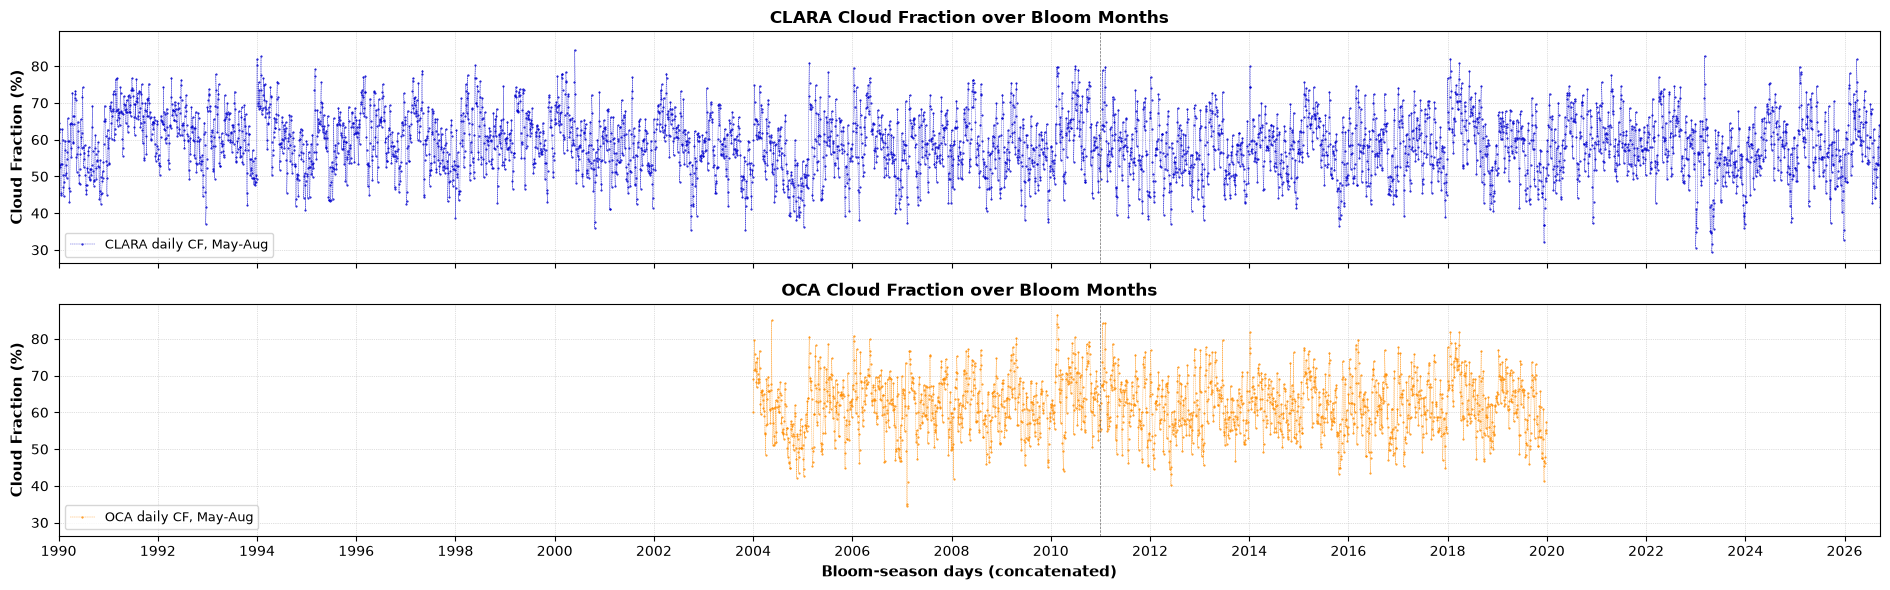

In [6]:
# Concatenated May-Aug axis: one sequence number per bloom-season day, shared by both datasets
seq = pd.Series(range(len(clara.index.union(oca.index))), index = clara.index.union(oca.index))
onset = seq[seq.index >= split].iloc[0]

# --- Shared settings for both panels ---
fig, axes = plt.subplots(2, 1, figsize = (19, 6), sharex = True, sharey = True)
panels = [(axes[0], "CLARA", clara, "mediumblue"), (axes[1], "OCA", oca, "darkorange")]
# ---------------------------------------------------------------------------

for ax, name, s, colour in panels:
    ax.plot(seq[s.index], s.values, linewidth = 0.25, linestyle = '--', marker = '.', markersize = 1,
            color = colour, label = f"{name} daily CF, May-Aug")
    for block, style, lw in [("Full", ':', 1.5), ("Pre-2011", '-', 2.0), ("Post-2011", '-', 2.0)]:
        r = results[(name, block)]
        #ax.plot(seq[r["dates"]], r["y_fit"], linestyle = style, linewidth = lw,
                #color = 'black' if block == "Full" else ('darkred' if block == "Pre-2011" else 'red'),
                #label = f"{block}: {r['total']:+.2f} pp (p = {r['p_val']:.3f})")
    ax.axvline(onset, color = 'dimgrey', linestyle = '--', linewidth = 0.5)
    ax.set_ylabel('Cloud Fraction (%)', fontsize = 11, weight = 'bold')
    ax.set_title(f"{name} Cloud Fraction over Bloom Months", fontsize = 12, weight = 'bold')
    ax.grid(True, color = 'silver', linestyle = ':', linewidth = 0.5)
    ax.legend(loc = 'lower left', fontsize = 9)
    ax.margins(x = 0)

# Year labels at the first bloom-season day of every second year
first_days = seq.groupby(seq.index.year).min()
axes[1].set_xticks(first_days.values[::2])
axes[1].set_xticklabels(first_days.index[::2])
axes[1].set_xlabel('Bloom-season days (concatenated)', fontsize = 11, weight = 'bold')
plt.tight_layout()
plt.show()

In [7]:
fig.savefig('CLARA_OCA_trends_prepost2011.png', dpi = 300, bbox_inches = 'tight')

### Comparison ▶▶ CLARA and OCA together, no trendlines

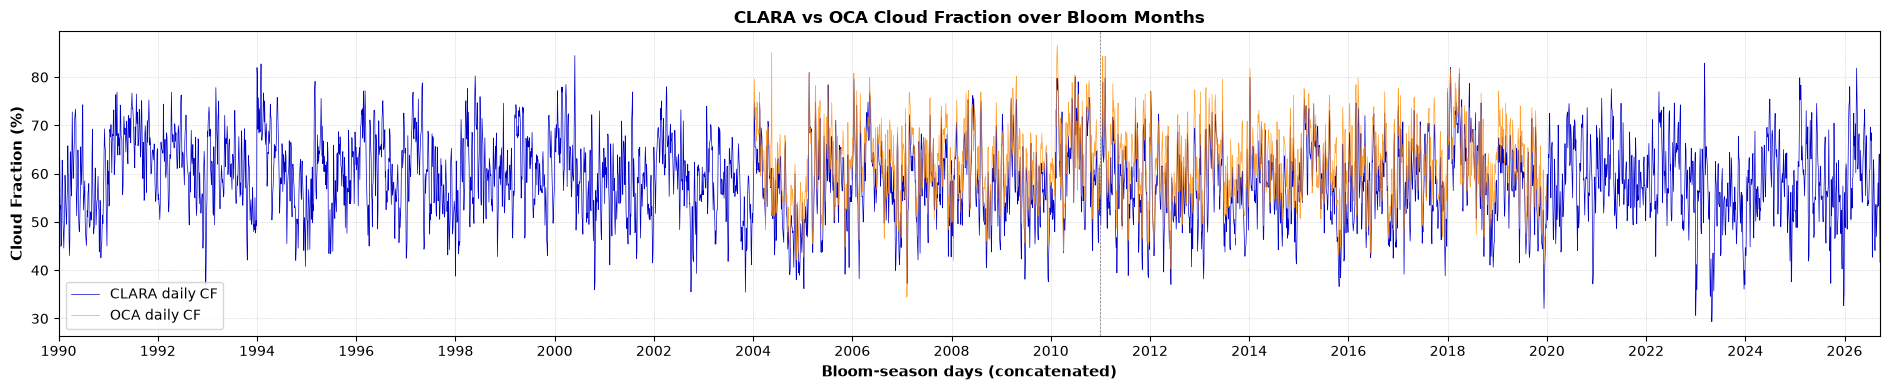

In [8]:
fig, ax = plt.subplots(figsize = (19, 4))

ax.plot(seq[clara.index], clara.values, linewidth = 0.5, color = 'mediumblue', label = 'CLARA daily CF')
ax.plot(seq[oca.index], oca.values, linewidth = 0.5, color = 'darkorange', alpha = 0.8, label = 'OCA daily CF')
ax.axvline(onset, color = 'dimgrey', linestyle = '--', linewidth = 0.5)

ax.set_xticks(first_days.values[::2])
ax.set_xticklabels(first_days.index[::2])
ax.margins(x = 0)
ax.set_xlabel('Bloom-season days (concatenated)', fontsize = 11, weight = 'bold')
ax.set_ylabel('Cloud Fraction (%)', fontsize = 11, weight = 'bold')
ax.set_title('CLARA vs OCA Cloud Fraction over Bloom Months', fontsize = 12, weight = 'bold')
ax.grid(True, color = 'silver', linestyle = ':', linewidth = 0.5)
ax.legend(loc = 'lower left')
plt.tight_layout()
plt.show()

In [9]:
fig.savefig('CLARA_OCA_comparison.png', dpi = 300, bbox_inches = 'tight')

### Weekly and monthly means ▶▶ trends, full record and pre-/post-2011

In [10]:
# Calendar weeks / months of the May-Aug daily series; off-season periods drop out as empty
means = {freq_name: {name: s.resample(rule).mean().dropna() for name, s in [("CLARA", clara), ("OCA", oca)]}
         for freq_name, rule in [("Weekly", "W"), ("Monthly", "MS")]}

agg_results = {}
for freq_name, series in means.items():
    for name, s in series.items():
        for block, sub in [("Full", s), ("Pre-2011", s[s.index < split]), ("Post-2011", s[s.index >= split])]:
            agg_results[(freq_name, name, block)] = trend_stats(sub.index.values, sub.values)
            agg_results[(freq_name, name, block)]["dates"] = sub.index

agg_summary = pd.DataFrame({k: {"start": v["dates"].min().date(), "end": v["dates"].max().date(),
                                "n": len(v["dates"]), "total_change_pp": round(v["total"], 2),
                                "slope_pp_per_decade": round(v["slope"] * 3652.5, 2),
                                "p_val": v["p_val"]} for k, v in agg_results.items()}).T
agg_summary

start         end    n total_change_pp  \
Weekly  CLARA Full       1990-05-06  2026-08-02  677           -3.31   
              Pre-2011   1990-05-06  2010-09-05  387           -3.62   
              Post-2011  2011-05-01  2026-08-02  290            0.78   
        OCA   Full       2004-05-02  2019-09-01  295            0.77   
              Pre-2011   2004-05-02  2010-09-05  130            3.64   
              Post-2011  2011-05-01  2019-09-01  165            0.66   
Monthly CLARA Full       1990-05-01  2026-07-01  147           -3.24   
              Pre-2011   1990-05-01  2010-08-01   84           -3.48   
              Post-2011  2011-05-01  2026-07-01   63            0.99   
        OCA   Full       2004-05-01  2019-08-01   64             0.5   
              Pre-2011   2004-05-01  2010-08-01   28            3.58   
              Post-2011  2011-05-01  2019-08-01   36             0.5   

                        slope_pp_per_decade     p_val  
Weekly  CLARA Full                    -0.91  0.000065  
              Pre-2011                -1.78  0.000707  
              Post-2011                0.51  0.530518  
        OCA   Full                      0.5  0.480221  
              Pre-2011                 5.74  0.019322  
              Post-2011                0.79  0.635892  
Monthly CLARA Full                     -0.9  0.008387  
              Pre-2011                -1.72  0.030419  
              Post-2011                0.66  0.579293  
        OCA   Full                     0.33  0.733835  
              Pre-2011                 5.72  0.081785  
              Post-2011                0.61  0.799213

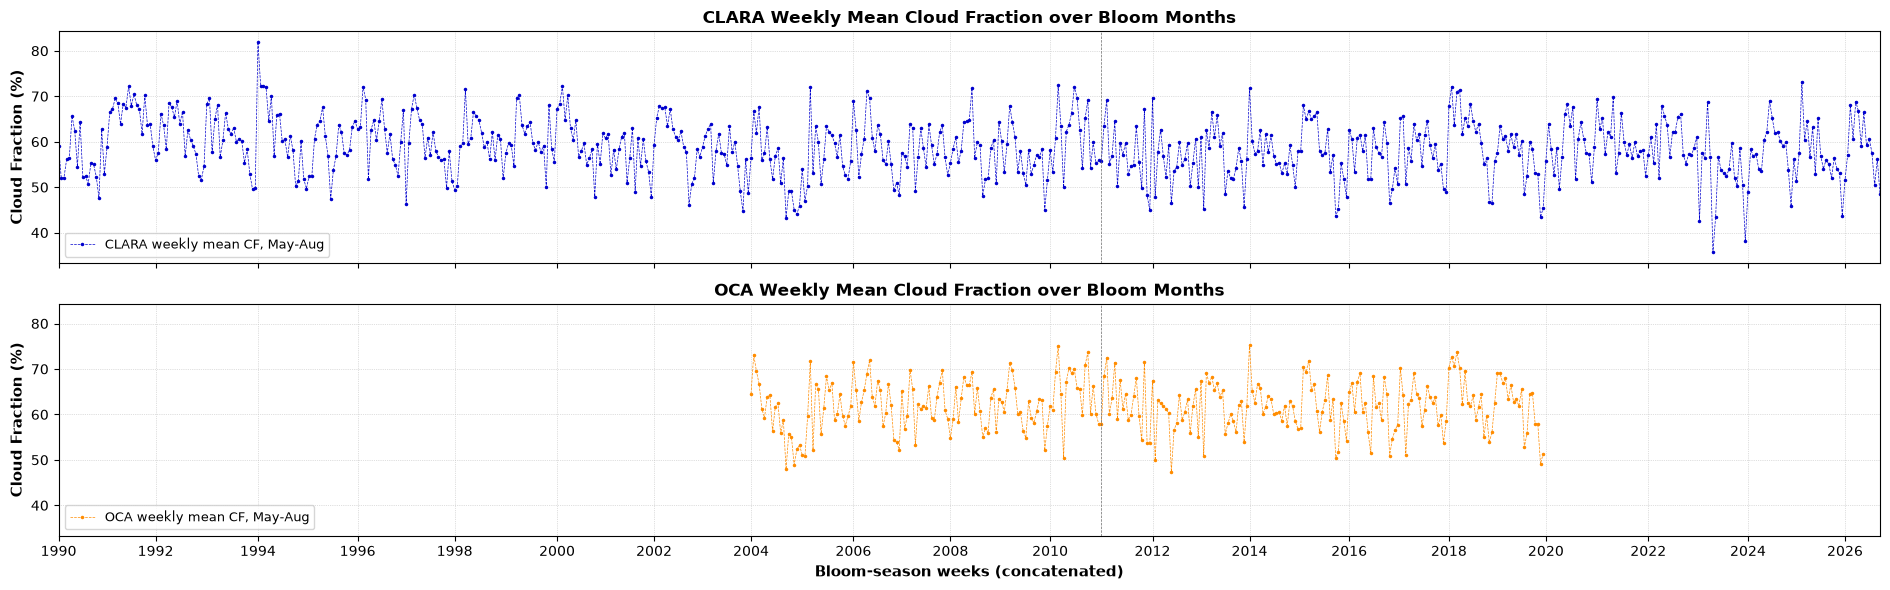

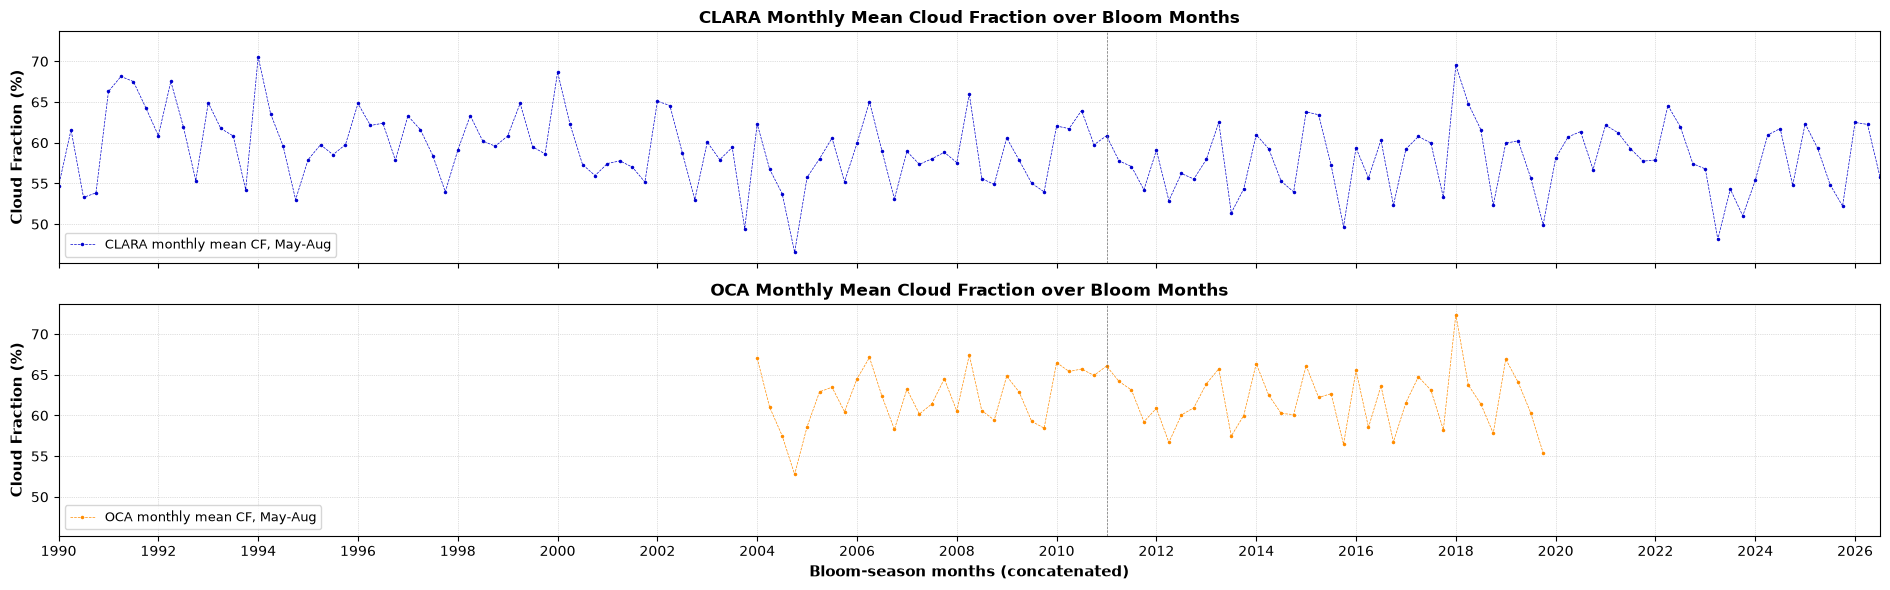

In [11]:
for freq_name, series in means.items():
    # Concatenated bloom-season axis for this averaging period, shared by both datasets
    idx = series["CLARA"].index.union(series["OCA"].index)
    seq_f = pd.Series(range(len(idx)), index = idx)
    onset_f = seq_f[seq_f.index >= split].iloc[0]
    first_f = seq_f.groupby(seq_f.index.year).min()

    fig, axes = plt.subplots(2, 1, figsize = (19, 6), sharex = True, sharey = True)

    for ax, name, colour in [(axes[0], "CLARA", "mediumblue"), (axes[1], "OCA", "darkorange")]:
        s = series[name]
        ax.plot(seq_f[s.index], s.values, linewidth = 0.5, linestyle = '--', marker = '.', markersize = 3,
                color = colour, label = f"{name} {freq_name.lower()} mean CF, May-Aug")
        #for block, style, lw in [("Full", ':', 1.5), ("Pre-2011", '-', 2.0), ("Post-2011", '-', 2.0)]:
            #r = agg_results[(freq_name, name, block)]
            #ax.plot(seq_f[r["dates"]], r["y_fit"], linestyle = style, linewidth = lw,
                    #color = 'black' if block == "Full" else ('darkred' if block == "Pre-2011" else 'red'),
                    #label = f"{block}: {r['total']:+.2f} pp (p = {r['p_val']:.3f})")
        ax.axvline(onset_f, color = 'dimgrey', linestyle = '--', linewidth = 0.5)
        ax.set_ylabel('Cloud Fraction (%)', fontsize = 11, weight = 'bold')
        ax.set_title(f"{name} {freq_name} Mean Cloud Fraction over Bloom Months", fontsize = 12, weight = 'bold')
        ax.grid(True, color = 'silver', linestyle = ':', linewidth = 0.5)
        ax.legend(loc = 'lower left', fontsize = 9)
        ax.margins(x = 0)

    axes[1].set_xticks(first_f.values[::2])
    axes[1].set_xticklabels(first_f.index[::2])
    axes[1].set_xlabel(f"Bloom-season {freq_name.lower().replace('ly', 's')} (concatenated)", fontsize = 11, weight = 'bold')
    plt.tight_layout()
    plt.show()
    fig.savefig(f'CLARA_OCA_trends_prepost2011_{freq_name.lower()}.png', dpi = 300, bbox_inches = 'tight')

### Comparison ▶▶ weekly and monthly CLARA and OCA together, no trendlines

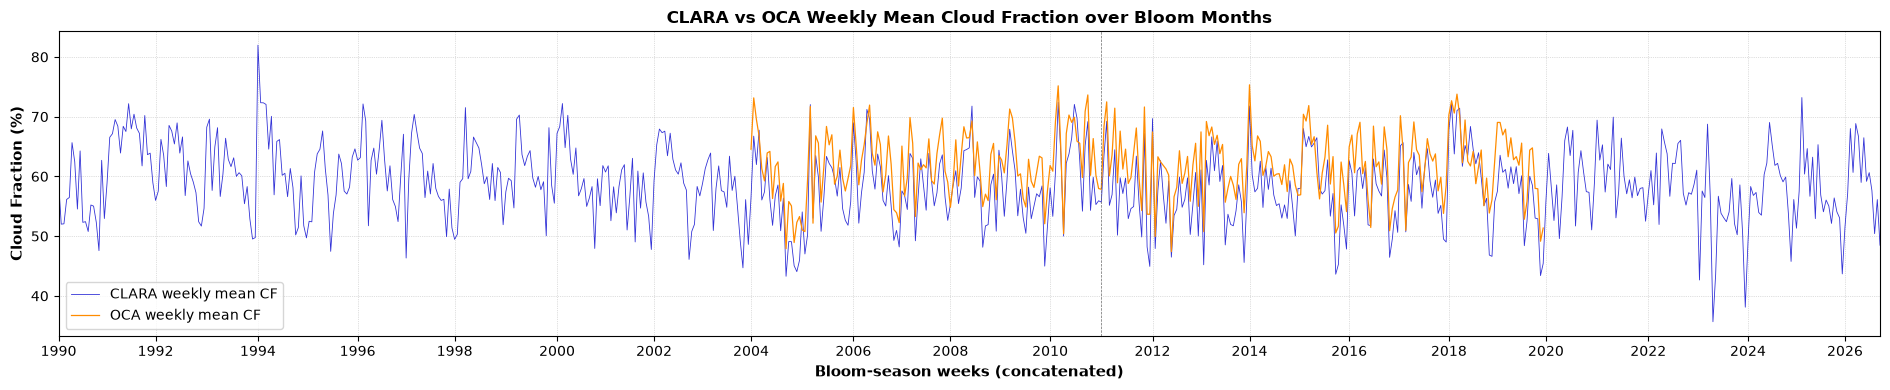

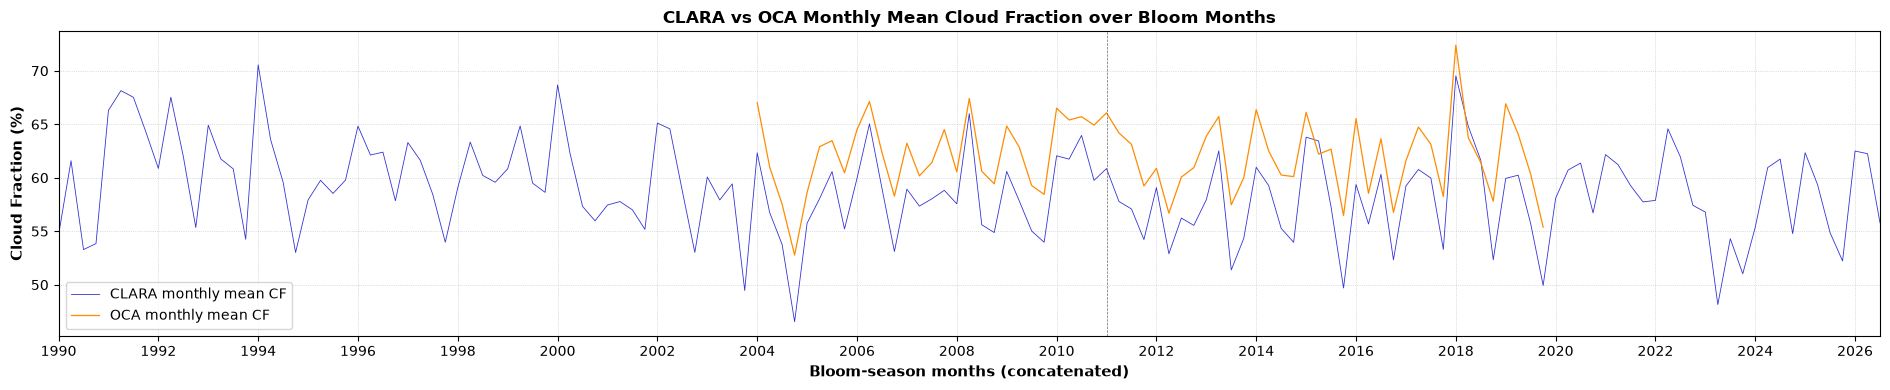

In [12]:
for freq_name, series in means.items():
    idx = series["CLARA"].index.union(series["OCA"].index)
    seq_f = pd.Series(range(len(idx)), index = idx)
    onset_f = seq_f[seq_f.index >= split].iloc[0]
    first_f = seq_f.groupby(seq_f.index.year).min()

    fig, ax = plt.subplots(figsize = (19, 4))
    ax.plot(seq_f[series["CLARA"].index], series["CLARA"].values, linewidth = 0.6, color = 'mediumblue',
            alpha = 0.8, label = f"CLARA {freq_name.lower()} mean CF")
    ax.plot(seq_f[series["OCA"].index], series["OCA"].values, linewidth = 0.9, color = 'darkorange', 
            label = f"OCA {freq_name.lower()} mean CF")
    ax.axvline(onset_f, color = 'dimgrey', linestyle = '--', linewidth = 0.5)

    ax.set_xticks(first_f.values[::2])
    ax.set_xticklabels(first_f.index[::2])
    ax.margins(x = 0)
    ax.set_xlabel(f"Bloom-season {freq_name.lower().replace('ly', 's')} (concatenated)", fontsize = 11, weight = 'bold')
    ax.set_ylabel('Cloud Fraction (%)', fontsize = 11, weight = 'bold')
    ax.set_title(f"CLARA vs OCA {freq_name} Mean Cloud Fraction over Bloom Months", fontsize = 12, weight = 'bold')
    ax.grid(True, color = 'silver', linestyle = ':', linewidth = 0.5)
    ax.legend(loc = 'lower left')
    plt.tight_layout()
    plt.show()
    fig.savefig(f'CLARA_OCA_comparison_{freq_name.lower()}.png', dpi = 300, bbox_inches = 'tight')